# 01 · Reconnaissance des données BDG2

**Objectif** : comprendre ce que contiennent les 4 fichiers téléchargés *avant* de décider quoi que ce soit.

**Ce qu'on vérifie** : les fichiers sont-ils les vrais (et pas des pointeurs Git LFS) ? Quelle est leur forme ? Quelles colonnes, quels types, combien de valeurs manquantes ? Le temps est-il régulier ?

**Ce qu'on produit** : `data/interim/dictionnaire-donnees.csv` (hors Git). Les constats importants seront recopiés plus tard dans l'ADR « choix du jeu de données » (`docs/adr/`).

> Rappel : on ne modifie jamais `data/raw/`. Les données ne sont pas dans Git.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")                       # ce notebook s'exécute depuis notebooks/
RAW = ROOT / "data" / "raw" / "bdg2"    # fichiers téléchargés (jamais modifiés, jamais dans Git)
INTERIM = ROOT / "data" / "interim"     # résultats intermédiaires (hors Git)
PROCESSED = ROOT / "data" / "processed" # jeu final (hors Git, DVC en S7)
for dossier in (INTERIM, PROCESSED):
    dossier.mkdir(parents=True, exist_ok=True)

SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def runs(masque):
    """Pour chaque heure où masque est True : longueur de la série de True qui la contient (0 sinon).
    Exemple : [F, T, T, T, F, T] -> [0, 3, 3, 3, 0, 1]"""
    groupe = (masque != masque.shift()).cumsum()
    return masque.groupby(groupe).transform("sum") * masque

def dominant(serie):
    """Valeur la plus fréquente d'une colonne (ou 'inconnu' si tout est vide)."""
    vc = serie.value_counts()
    return vc.index[0] if len(vc) else "inconnu"

def plus_long_trou(serie):
    """Plus longue suite d'heures manquantes consécutives."""
    return int(runs(serie.isna()).max())

## 1. Les fichiers sont-ils les vrais ?

Les CSV de BDG2 sont stockés avec **Git LFS** : si le téléchargement a échoué, on obtient un petit texte de ~130 octets (un « pointeur ») au lieu des données. On le détecte tout de suite pour ne pas perdre de temps.

In [3]:
FICHIERS = {
    "metadata": RAW / "metadata.csv",
    "weather": RAW / "weather.csv",
    "elec_raw": RAW / "electricity.csv",
    "elec_cleaned": RAW / "electricity_cleaned.csv",
}
for nom, chemin in FICHIERS.items():
    assert chemin.exists(), f"Fichier manquant : {chemin}. Vérifie le nom et le dossier data/raw/bdg2/"
    with open(chemin, "rb") as f:
        pointeur = f.read(60).startswith(b"version https://git-lfs")
    taille = chemin.stat().st_size / 1e6
    print(f"{nom:13s} {taille:8.2f} Mo   {'POINTEUR LFS : mauvais fichier' if pointeur else 'OK'}")
    assert not pointeur, f"{chemin} est un pointeur Git LFS, pas les données : refais le téléchargement (voir le guide personnel, section 5)."

metadata          0.25 Mo   OK
weather          16.21 Mo   OK
elec_raw        164.24 Mo   OK
elec_cleaned    174.98 Mo   OK


### Les fichiers sont-ils identiques aux originaux ?

On compare la **taille** et l'**empreinte SHA-256** à celles des fichiers officiels de BDG2 (lues dans les pointeurs Git LFS du dépôt). Un fichier qui diffère a été **modifié** : par exemple ouvert puis réenregistré dans Excel, ce qui peut changer le format des dates, les chiffres après la virgule ou les valeurs vides. Dans ce cas, **retélécharge l'original** et n'ouvre plus les CSV dans Excel.

In [4]:
import hashlib

OFFICIEL = {   # taille en octets, SHA-256 (pointeurs Git LFS du dépôt BDG2, branche master)
    "metadata": (272_024, "992d0b29f24f96ad4332bc4dbb534b7bdd7dd2689aad093f94e93068ecddca02"),
    "weather": (19_457_782, "a8189f1c6acdf3b9933a9e6354b8e7c1278cd56a7075929623a17565d44f04bd"),
    "elec_raw": (174_239_039, "039d909d8981e2d69eaeb366144e6ab7e84fa5e7e216aee42bddd95384a66418"),
    "elec_cleaned": (174_977_911, "b6ffc9b4dfcefe5c753594730a08ae822b0d50fec6815abb8f185591e6c630a3"),
}

def sha256(chemin):
    h = hashlib.sha256()
    with open(chemin, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()

modifies = []
for nom, (taille, empreinte) in OFFICIEL.items():
    reel = FICHIERS[nom].stat().st_size
    identique = reel == taille and sha256(FICHIERS[nom]) == empreinte
    print(f"{nom:13s} taille {reel:>12,} (officielle {taille:>12,})  ->  {'identique à l original' if identique else 'DIFFÈRE de l original'}".replace(",", " "))
    if not identique:
        modifies.append(nom)
if modifies:
    print("\nATTENTION : fichiers modifiés :", modifies, "\n-> retélécharger les originaux (voir le guide) avant de continuer.")

metadata      taille      247 993 (officielle      272 024)  ->  DIFFÈRE de l original
weather       taille   16 211 326 (officielle   19 457 782)  ->  DIFFÈRE de l original
elec_raw      taille  164 239 748 (officielle  174 239 039)  ->  DIFFÈRE de l original
elec_cleaned  taille  174 977 911 (officielle  174 977 911)  ->  identique à l original

ATTENTION : fichiers modifiés : ['metadata', 'weather', 'elec_raw'] 
-> retélécharger les originaux (voir le guide) avant de continuer.


In [5]:
# Format des dates tel qu'il est écrit dans les fichiers (les originaux et un fichier réenregistré par Excel diffèrent)
for nom in ("elec_raw", "elec_cleaned", "weather"):
    with open(FICHIERS[nom], encoding="utf-8") as f:
        f.readline()
        print(f"{nom:13s} 1re ligne de données :", f.readline().strip()[:70])

elec_raw      1re ligne de données : 1/1/2016 0:00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,12.6024,0,0,0,,0,0,0,0,0
elec_cleaned  1re ligne de données : 2016-01-01 00:00:00,,,,,,,,,,,,,,,,,12.6024,,,,,,,,,,,,,,,,,,,,,,,,,,,
weather       1re ligne de données : 1/1/2016 0:00,Panther,19.4,,19.4,0,,,0,0


## 2. Premier coup d'œil sans tout charger

`nrows=3` ne lit que 3 lignes : c'est instantané, même sur un fichier de 175 Mo. On regarde les noms de colonnes et ce qu'une ligne représente.

In [6]:
print("--- metadata (1 ligne = 1 bâtiment) ---")
display(pd.read_csv(FICHIERS["metadata"], nrows=3).T)
print("--- electricity raw (1 ligne = 1 heure, 1 colonne = 1 bâtiment) ---")
display(pd.read_csv(FICHIERS["elec_raw"], nrows=3).iloc[:, :5])
print("--- weather (1 ligne = 1 heure d'un site) ---")
display(pd.read_csv(FICHIERS["weather"], nrows=3).T)

--- metadata (1 ligne = 1 bâtiment) ---


,0,1,2
building_id,Panther_lodging_Dean,Panther_lodging_Shelia,Panther_lodging_Ricky
site_id,Panther,Panther,Panther
building_id_kaggle,NaN,NaN,NaN
site_id_kaggle,0,0,0
primaryspaceusage,Lodging/residential,Lodging/residential,Lodging/residential
sub_primaryspaceusage,Residence Hall,Residence Hall,Residence Hall
sqm,508.80,929.00,483.10
sqft,5477,10000,5200
lat,28.52,28.52,28.52
lng,-81.38,-81.38,-81.38


--- electricity raw (1 ligne = 1 heure, 1 colonne = 1 bâtiment) ---


,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie
0,1/1/2016 0:00,0,0,0,0
1,1/1/2016 1:00,0,0,0,0
2,1/1/2016 2:00,0,0,0,0


--- weather (1 ligne = 1 heure d'un site) ---


,0,1,2
timestamp,1/1/2016 0:00,1/1/2016 1:00,1/1/2016 2:00
site_id,Panther,Panther,Panther
airTemperature,19.40,21.10,21.10
cloudCoverage,NaN,6.00,NaN
dewTemperature,19.40,21.10,21.10
precipDepth1HR,0,-1,0
precipDepth6HR,NaN,NaN,NaN
seaLvlPressure,NaN,1019.40,1018.80
windDirection,0,0,210
windSpeed,0.00,0.00,1.50


## 3. Chargement complet et vérification des colonnes attendues

On charge l'électricité *raw* en entier (≈ 175 Mo : ça tient en mémoire). Pour le fichier `cleaned`, on ne lit que l'en-tête : on ne l'utilisera qu'en comparaison, plus tard, sur 20 bâtiments seulement.

In [7]:
meta = pd.read_csv(FICHIERS["metadata"])
elec = pd.read_csv(FICHIERS["elec_raw"], parse_dates=["timestamp"], index_col="timestamp")
weather = pd.read_csv(FICHIERS["weather"], parse_dates=["timestamp"])
colonnes_cleaned = set(pd.read_csv(FICHIERS["elec_cleaned"], nrows=0).columns) - {"timestamp"}

ATTENDUES_META = {"building_id", "site_id", "primaryspaceusage", "sqm", "timezone"}
ATTENDUES_WEATHER = {"timestamp", "site_id", "airTemperature"}
manque_meta = ATTENDUES_META - set(meta.columns)
manque_weather = ATTENDUES_WEATHER - set(weather.columns)
assert not manque_meta, f"Colonnes absentes de metadata : {manque_meta}. Colonnes réelles : {meta.columns.tolist()}"
assert not manque_weather, f"Colonnes absentes de weather : {manque_weather}. Colonnes réelles : {weather.columns.tolist()}"

print("metadata", meta.shape, "| electricity raw", elec.shape, "| weather", weather.shape)
print("mêmes bâtiments en raw et cleaned :", set(elec.columns) == colonnes_cleaned)
print("colonnes d'électricité sans ligne dans metadata :", len(set(elec.columns) - set(meta["building_id"])))

# La colonne 'electricity' de metadata (Yes / vide) annonce quels bâtiments ont un compteur : cohérent avec le fichier ?
if "electricity" in meta.columns:
    annonces = set(meta.loc[meta["electricity"].notna(), "building_id"])
    print("bâtiments annoncés avec électricité :", len(annonces), "| colonnes du fichier :", elec.shape[1],
          "| annoncés mais absents du fichier :", len(annonces - set(elec.columns)))

metadata (1636, 32) | electricity raw (17544, 1578) | weather (331166, 10)
mêmes bâtiments en raw et cleaned : True
colonnes d'électricité sans ligne dans metadata : 0
bâtiments annoncés avec électricité : 1578 | colonnes du fichier : 1578 | annoncés mais absents du fichier : 0


## 4. Le temps est-il bien structuré ?

Une série temporelle suppose un pas **régulier** (1 h), un index **trié** et **sans doublon**. Sinon, les retards (« la veille », « la semaine passée ») seront faux plus tard.

In [8]:
attendu = pd.date_range(elec.index.min(), elec.index.max(), freq="h")
print("début / fin           :", elec.index.min(), "→", elec.index.max())
print("nb d'heures           :", len(elec), "(attendu 17 544 pour 2 ans)")
print("index trié            :", elec.index.is_monotonic_increasing)
print("index sans doublon    :", elec.index.is_unique)
print("heures manquantes     :", len(attendu.difference(elec.index)))
print("heures en trop        :", len(elec.index.difference(attendu)))

heures_par_jour = elec.index.to_series().groupby(elec.index.normalize()).size()
print("\nnb d'heures par jour (24 partout = pas de saut d'heure d'été dans l'index) :")
print(heures_par_jour.value_counts())
assert len(elec) == 17544, "Le nombre d'heures diffère de 17 544 : à noter (ADR) et à comprendre."

début / fin           : 2016-01-01 00:00:00 → 2017-12-31 23:00:00
nb d'heures           : 17544 (attendu 17 544 pour 2 ans)
index trié            : True
index sans doublon    : True
heures manquantes     : 0
heures en trop        : 0

nb d'heures par jour (24 partout = pas de saut d'heure d'été dans l'index) :
timestamp
24    731
Name: count, dtype: int64


## 5. Dictionnaire des colonnes

Pour chaque colonne : type, % de manquants, nombre de valeurs distinctes, min et max. C'est la carte d'identité du jeu de données, à garder comme trace.

In [9]:
def dictionnaire(df, nom):
    d = pd.DataFrame({
        "fichier": nom,
        "type": df.dtypes.astype(str),
        "pct_manquant": (df.isna().mean() * 100).round(1),
        "nb_distinctes": df.nunique(),
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
    })
    d.index.name = "colonne"
    return d

dico = pd.concat([dictionnaire(meta, "metadata"), dictionnaire(weather, "weather")])
dico.to_csv(INTERIM / "dictionnaire-donnees.csv")
dico

,fichier,type,pct_manquant,nb_distinctes,min,max
colonne,,,,,,
building_id,metadata,str,0.00,1636,NaN,NaN
building_id_kaggle,metadata,float64,11.40,1449,0.00,1448.00
chilledwater,metadata,str,66.10,1,NaN,NaN
date_opened,metadata,str,98.70,21,NaN,NaN
electricity,metadata,str,3.50,1,NaN,NaN
energystarscore,metadata,str,90.00,33,NaN,NaN
eui,metadata,str,81.70,263,NaN,NaN
gas,metadata,str,89.20,1,NaN,NaN
heatingtype,metadata,str,86.90,12,NaN,NaN


In [10]:
# L'électricité a ~1 500 colonnes (une par bâtiment) : on résume au lieu de lister
resume_elec = elec.describe().T[["min", "50%", "max"]]
print("Résumé sur tous les bâtiments (min / médiane / max de chaque bâtiment) :")
display(resume_elec.describe().round(1))
print("Types des colonnes d'électricité :", elec.dtypes.astype(str).value_counts().to_dict())

vides = elec.columns[elec.isna().all()]
zeros = elec == 0
print("colonnes entièrement vides :", len(vides), list(vides))
print("bâtiments avec au moins une heure à zéro :", int(zeros.any().sum()), "sur", elec.shape[1])
print(f"part des mesures égales à zéro (tous bâtiments) : {zeros.sum().sum() / elec.notna().sum().sum() * 100:.1f} %")

Résumé sur tous les bâtiments (min / médiane / max de chaque bâtiment) :


,min,50%,max
count,1576.00,1576.00,1576.00
mean,19.10,132.60,659.20
std,60.60,227.80,5991.10
min,0.00,0.00,0.00
25%,0.00,18.20,61.50
50%,0.00,54.70,162.20
75%,6.60,143.20,373.20
max,583.50,3017.60,221228.00


Types des colonnes d'électricité : {'float64': 1547, 'int64': 31}
colonnes entièrement vides : 2 ['Rat_public_Ulysses', 'Eagle_lodging_Garland']
bâtiments avec au moins une heure à zéro : 1006 sur 1578
part des mesures égales à zéro (tous bâtiments) : 4.4 %


### Météo : complétude par site

La météo est fournie **par site**. On vérifie, pour chaque site, le nombre d'heures présentes (17 544 attendues), les doublons et le % de valeurs manquantes de chaque variable. Une variable très vide sur l'ensemble des sites peut être correcte sur un site précis : c'est ce tableau qui permet de choisir.

In [11]:
meteo = weather.drop_duplicates(["site_id", "timestamp"])
variables = [c for c in weather.columns if c not in ("site_id", "timestamp")]
completude = pd.DataFrame({
    "heures": meteo.groupby("site_id").size(),
    "doublons": weather.groupby("site_id").size() - meteo.groupby("site_id").size(),
})
completude["heures_manquantes"] = 17544 - completude["heures"]
nan_par_variable = (meteo[variables].isna().groupby(meteo["site_id"]).mean() * 100).round(1)
print("lignes de météo :", len(weather), "| attendues pour 19 sites :", 19 * 17544)
pd.concat([completude, nan_par_variable], axis=1)

lignes de météo : 331166 | attendues pour 19 sites : 333336


,heures,doublons,heures_manquantes,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
site_id,,,,,,,,,,,
Bear,17542,0,2,0.00,46.40,0.00,8.40,98.10,0.80,1.10,0.00
Bobcat,17525,0,19,0.20,28.10,0.20,0.20,96.70,1.40,6.00,0.80
Bull,17529,0,15,0.20,39.50,0.70,0.10,97.30,2.90,29.40,1.30
Cockatoo,16975,0,569,0.00,54.10,0.00,78.80,94.10,6.90,2.60,0.20
Crow,16860,0,684,0.00,100.00,0.30,90.00,83.30,0.20,0.00,0.00
Eagle,17536,0,8,0.00,40.00,0.00,0.50,96.30,1.20,3.00,0.20
Fox,17543,0,1,0.00,28.30,0.00,0.40,99.10,0.30,6.90,0.10
Gator,17544,0,0,0.00,43.00,0.00,0.10,96.30,1.80,2.80,0.00
Hog,17542,0,2,0.00,49.20,0.00,0.30,95.80,1.20,2.50,0.00


In [12]:
# Valeurs inhabituelles de la météo (plages, valeurs spéciales)
print("valeurs égales à -1 (précipitations) :", {c: int((weather[c] == -1).sum()) for c in ("precipDepth1HR", "precipDepth6HR") if c in weather})
weather[variables].describe(percentiles=[0.01, 0.5, 0.99]).T

valeurs égales à -1 (précipitations) : {'precipDepth1HR': 12313, 'precipDepth6HR': 3582}


,count,mean,std,min,1%,50%,99%,max
airTemperature,331038.00,14.24,9.99,-28.90,-11.70,14.40,35.60,48.30
cloudCoverage,160179.00,1.92,2.55,0.00,0.00,0.00,8.00,9.00
dewTemperature,330838.00,7.65,9.20,-35.00,-17.80,8.50,23.90,26.70
precipDepth1HR,197980.00,0.96,8.27,-1.00,-1.00,0.00,25.00,597.00
precipDepth6HR,18162.00,13.54,43.80,-1.00,-1.00,0.00,204.95,770.00
seaLvlPressure,309542.00,1016.06,8.05,968.20,992.70,1016.20,1035.50,1050.10
windDirection,318161.00,184.39,111.57,0.00,0.00,200.00,360.00,360.00
windSpeed,330592.00,3.57,2.34,0.00,0.00,3.10,10.30,24.20


## 6. Qui sont les bâtiments ?

(Ce tableau compte **tous** les bâtiments de `metadata`, avec ou sans compteur d'électricité ; celui du notebook 02 ne compte que ceux qui ont de l'électricité. `usage_vide` signale les sites dont l'usage n'est pas renseigné.)

In [13]:
print(meta["primaryspaceusage"].value_counts(dropna=False))

primaryspaceusage
Education                        617
Office                           307
Entertainment/public assembly    204
Lodging/residential              168
Public services                  166
Other                             29
Healthcare                        29
Parking                           24
NaN                               21
Warehouse/storage                 15
Manufacturing/industrial          13
Retail                            12
Services                          11
Technology/science                 7
Food sales and service             6
Utility                            4
Religious worship                  3
Name: count, dtype: int64


In [14]:
par_site = meta.groupby("site_id").agg(
    nb_batiments=("building_id", "size"),
    nb_usages=("primaryspaceusage", "nunique"),
    usage_dominant=("primaryspaceusage", dominant),
    usage_vide=("primaryspaceusage", lambda s: int(s.isna().sum())),
    fuseau=("timezone", lambda s: ", ".join(sorted(s.dropna().unique()))),
)
par_site.sort_values("nb_batiments", ascending=False)

,nb_batiments,nb_usages,usage_dominant,usage_vide,fuseau
site_id,,,,,
Rat,305,11,Education,0,US/Eastern
Hog,163,13,Office,0,US/Central
Lamb,147,10,Education,0,Europe/London
Fox,137,12,Education,0,US/Mountain
Panther,136,7,Lodging/residential,0,US/Eastern
Bull,124,6,Education,0,US/Central
Cockatoo,124,10,Education,0,US/Eastern
Eagle,106,7,Office,0,US/Eastern
Bear,92,7,Education,0,US/Pacific


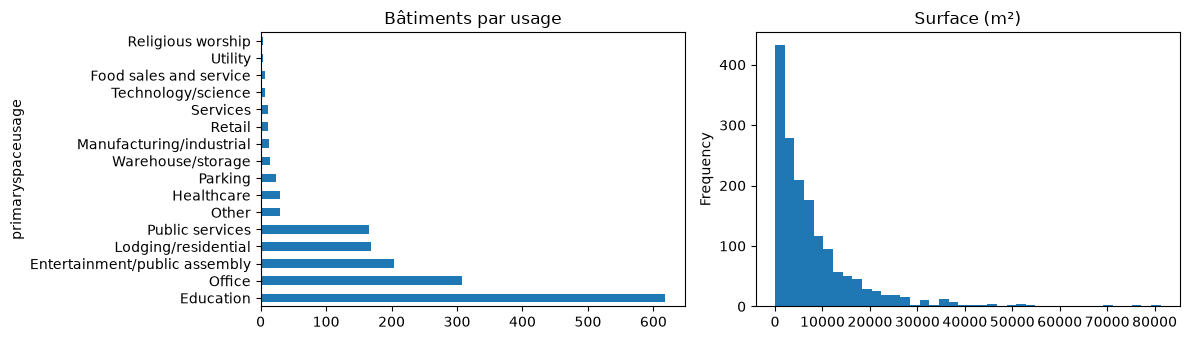

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
meta["primaryspaceusage"].value_counts().plot.barh(ax=ax[0], title="Bâtiments par usage")
meta["sqm"].dropna().plot.hist(bins=40, ax=ax[1], title="Surface (m²)")
plt.tight_layout()

## 7. Ce que ce notebook nous apprend (à noter pour l'ADR « choix du jeu de données »)

| Question | Réponse observée |
|---|---|
| Fichiers authentiques (pas de pointeur LFS) ? | [...] |
| Formes (lignes × colonnes) | metadata [...] · electricity [...] · weather [...] |
| Index temporel : trié, unique, pas de 1 h, 17 544 h ? | [...] |
| Jours à 23 ou 25 h (heure d'été) ? | [...] |
| Colonnes de `metadata` utiles pour nous | [...] |
| Colonnes de `weather` utiles et leur % de manquants | [...] |
| Sites : nombre, tailles, fuseaux | [...] |
| Usages les plus fréquents | [...] |
| Surprises ou points à creuser | [...] |